# 2. The linear power spectrum

This notebook follows Sec. 2.3 of Paper I.
It shows the two spectra every backend returns, the box `emu_pk` was trained on, the agreement of the emulator with CLASS, and the derivatives of $\ln P$ with respect to the ten parameters, ending on the figure of the $P(k)$ gradients.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import time

from ggah_mod.cosmology import PLANCK18, make_pk

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = True


## Two backends, two spectra

`ACCURATE` takes its spectrum from a Boltzmann solver, CLASS by default and CAMB as the alternative; `DIFFERENTIABLE` takes it from `emu_pk`, a neural-network emulator of the linear spectrum written in JAX.
`emu_pk` was trained on 150 000 CAMB 1.6.6 solves over $\omega_{\rm b}$, $\omega_{\rm cdm}$, $h$, $w_0$, $w_a$, $\Omega_k$ and $\sum m_\nu$ with two mass ratios, for $z \le 5$ and $k \le 300\,h\,{\rm Mpc}^{-1}$.
$n_{\rm s}$ and $\ln(10^{10}A_{\rm s})$ are restored in closed form rather than learned.

Each backend returns the total-matter spectrum $P_{\rm m}(k,z)$ and the CDM+baryon spectrum $P_{\rm cb}(k,z)$, in $(h^{-1}{\rm Mpc})^3$ with $k$ in $h\,{\rm Mpc}^{-1}$.
Haloes form out of the CDM+baryon field, so the halo layer uses $P_{\rm cb}$; lensing sees all the matter and uses $P_{\rm m}$.

emu_pk network inputs: ('omega_b', 'omega_cdm', 'h', 'n_s', 'ln10A_s', 'sum_mnu', 'w0', 'wa', 'Omega_k', 'nu_r1', 'nu_r2')
differentiable: True


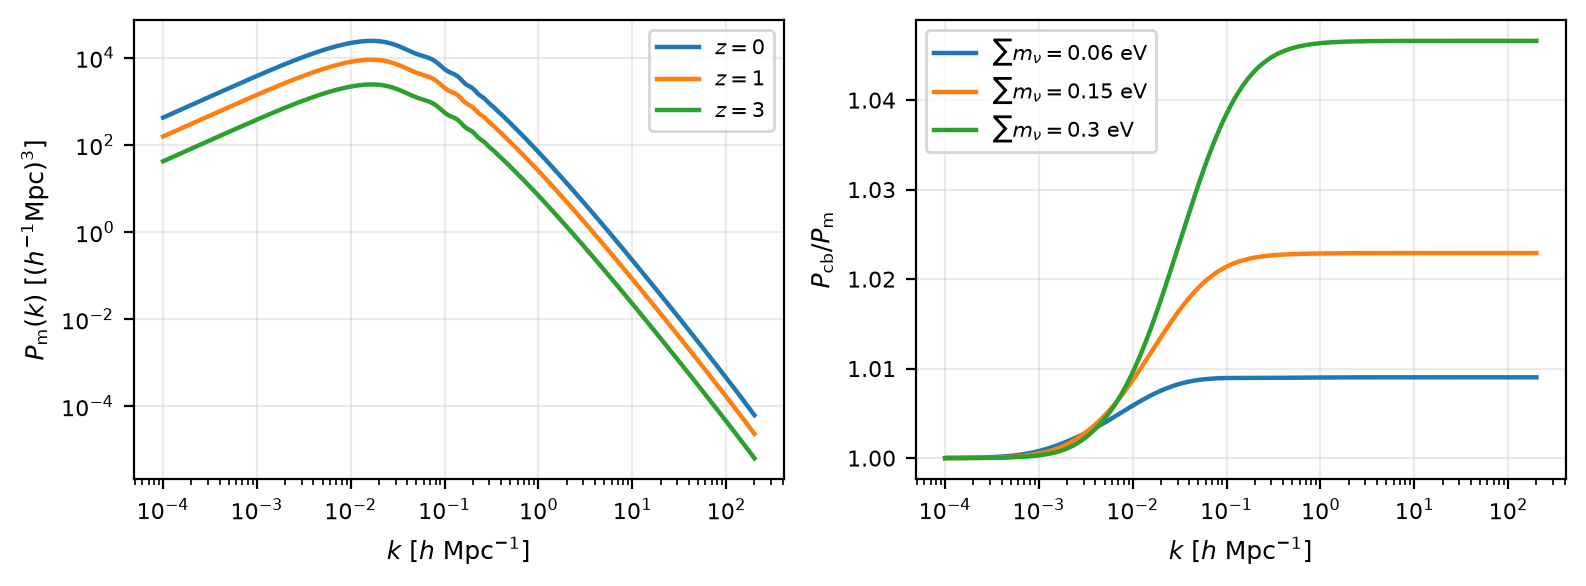

In [2]:
import emu_pk.box

pk = make_pk("emu_pk")
print("emu_pk network inputs:", emu_pk.box.PARAMS)
print("differentiable:", pk.differentiable)

k = np.logspace(-4, np.log10(200.0), 512)
zs = np.array([0.0, 1.0, 3.0])
P_m = pk.pk(k, zs, PLANCK18)          # several redshifts in one call: shape (3, 512)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(8.0, 3.0))
for zi, row in zip(zs, P_m):
    a0.loglog(k, row, label=f"$z = {zi:g}$")
a0.set(xlabel=r"$k$ [$h$ Mpc$^{-1}$]", ylabel=r"$P_{\rm m}(k)$ [$(h^{-1}{\rm Mpc})^3$]")
a0.legend()
for sum_mnu in (0.06, 0.15, 0.3):
    cc = PLANCK18.replace(sum_mnu=sum_mnu)
    a1.semilogx(k, pk.pk_cb(k, 0.0, cc) / pk.pk(k, 0.0, cc), label=rf"$\sum m_\nu = {sum_mnu}$ eV")
a1.set(xlabel=r"$k$ [$h$ Mpc$^{-1}$]", ylabel=r"$P_{\rm cb}/P_{\rm m}$")
a1.legend()
fig.tight_layout()

The emulator refuses a cosmology outside its training box rather than extrapolating.

In [3]:
try:
    pk.pk(k, 0.0, PLANCK18.replace(sum_mnu=0.8))
except ValueError as err:
    print(err)

outside the emulator training box, where the network extrapolates with no accuracy guarantee: sum_mnu = 0.8 not in [0, 0.6].


## The control at zero mass

With massless neutrinos the two fields are one, so $P_{\rm cb}/P_{\rm m} - 1$ must vanish.
CLASS and CAMB return zero identically.
`emu_pk` has one output head per spectrum and nothing ties them together, so it returns a small residual.

In [4]:
c0 = PLANCK18.replace(sum_mnu=0.0)
kk = np.logspace(-2, np.log10(0.5), 200)
resid = float(np.max(np.abs(pk.pk_cb(kk, 0.0, c0) / pk.pk(kk, 0.0, c0) - 1)))
print(f"max |P_cb/P_m - 1| at zero mass = {resid:.1e}   (paper: 3.0e-4)")
assert 1e-4 < resid < 1e-3

max |P_cb/P_m - 1| at zero mass = 3.0e-04   (paper: 3.0e-4)


## The emulator against CLASS

`emu_pk` inherits the accuracy of its training set, CAMB at raised precision, which is $3.2\times10^{-5}$ from CAMB's converged answer at the fiducial.
Against held-out spectra it is accurate to 0.064 per cent at the median and 0.18 per cent at most.
The comparison below runs only if `classy` is installed (`pip install "ggah_mod[reference]"`); a CLASS solve takes about 20 s.
The difference is then the emulator's error plus the distance between CLASS and CAMB at their precision settings, which the paper puts at $6.1\times10^{-4}$.

In [5]:
try:
    pk_class = make_pk("class")
    kc = np.logspace(-2, np.log10(0.5), 200)
    for zi in (0.0, 1.0):
        r = pk.pk(kc, zi, PLANCK18) / pk_class.pk(kc, zi, PLANCK18) - 1
        print(f"z = {zi:g}: max |emu_pk/CLASS - 1| on 0.01 < k < 0.5 = {np.max(np.abs(r)):.1e}")
except ImportError:
    print("classy is not installed: skipped")

z = 0: max |emu_pk/CLASS - 1| on 0.01 < k < 0.5 = 9.7e-04


z = 1: max |emu_pk/CLASS - 1| on 0.01 < k < 0.5 = 8.8e-04


## Derivatives

`jax.jacfwd` differentiates $\ln P_{\rm m}(k)$ through the network, one parameter at a time, in the convention of notebook 01 (logarithmic for the five positive scales, absolute for the other five).
Two directions are known in closed form, which checks that they are applied and not fitted.
The amplitude enters $\ln P$ as an additive constant, so $\partial\ln P/\partial\ln(10^{10}A_{\rm s}) = 1$.
The tilt gives $\partial\ln P/\partial n_{\rm s} = \ln(k/k_{\rm pivot})$, with $k_{\rm pivot} = 0.05\,{\rm Mpc}^{-1} = 0.05/h\;h\,{\rm Mpc}^{-1}$.

In [6]:
k = np.logspace(-3, np.log10(200.0), 200 if FAST else 400)
kj = jnp.asarray(k)
c = PLANCK18

g, gr = {}, {}
for p in T.DPARAMS:
    v0 = float(getattr(c, p))
    scale = v0 if p in T.DLOG else 1.0
    lnP = lambda v, p=p: jnp.log(pk.pk(kj, 0.0, c.replace(**{p: v})))
    ratio = lambda v, p=p: (jnp.log(pk.pk_cb(kj, 0.0, c.replace(**{p: v})))
                            - jnp.log(pk.pk(kj, 0.0, c.replace(**{p: v}))))
    g[p] = np.asarray(jax.jacfwd(lnP)(v0)) * scale
    gr[p] = np.asarray(jax.jacfwd(ratio)(v0)) * scale

print(f"{'':10s}{'dlnP at k=0.1':>15s}{'dln(Pcb/Pm) at k=1':>21s}")
for p in T.DPARAMS:
    print(f"{p:10s}{np.interp(0.1, k, g[p]):+15.4g}{np.interp(1.0, k, gr[p]):+21.4g}")

            dlnP at k=0.1   dln(Pcb/Pm) at k=1
Omega_m            +1.406            -0.009041
Omega_b           -0.5644           +8.397e-05
h                  +2.052             -0.01788
sum_mnu            -0.035            +0.009094
T_cmb            -0.01899           +0.0001221
n_s               +0.2979                   +0
ln10A_s                +1                   +0
w0                -0.4958           +3.369e-05
wa                -0.1521           +8.055e-05
Omega_k            -1.925            -0.003843


In [7]:
amp = float(np.max(np.abs(g["ln10A_s"] - 1.0)))
k_piv = 0.05 / c.h
tilt = float(np.max(np.abs(g["n_s"] - np.log(k / k_piv))))
print(f"d lnP / d ln10A_s = 1 to {amp:.1e}")
print(f"d lnP / d n_s = ln(k/k_pivot) to {tilt:.1e}   (paper: 5e-13)")
assert amp < 1e-12 and tilt < 1e-11

d lnP / d ln10A_s = 1 to 0.0e+00
d lnP / d n_s = ln(k/k_pivot) to 5.4e-13   (paper: 5e-13)


A central finite difference checks the automatic derivative.

In [8]:
for p, step in (("Omega_m", 1e-4), ("h", 1e-4), ("w0", 1e-4), ("sum_mnu", 1e-3)):
    v0 = float(getattr(c, p))
    scale = v0 if p in T.DLOG else 1.0
    lnP = lambda v: np.log(np.asarray(pk.pk(kj, 0.0, c.replace(**{p: v}))))
    fd = (lnP(v0 + step) - lnP(v0 - step)) / (2 * step) * scale
    print(f"{p:8s} max |autodiff - finite difference| / max |derivative| = "
          f"{np.max(np.abs(g[p] - fd)) / np.max(np.abs(g[p])):.1e}")

Omega_m  max |autodiff - finite difference| / max |derivative| = 6.4e-08
h        max |autodiff - finite difference| / max |derivative| = 1.4e-08
w0       max |autodiff - finite difference| / max |derivative| = 1.0e-08
sum_mnu  max |autodiff - finite difference| / max |derivative| = 9.1e-06


## The figure

Fig. 3 of the paper.
Panel (a) is $\partial\ln P_{\rm m}/\partial\theta$; the wiggles of $\Omega_{\rm m}$ and $h$ around $k\sim0.1\,h\,{\rm Mpc}^{-1}$ are the acoustic scale moving with the parameter.
Panel (b) is the same derivatives of the ratio $P_{\rm cb}/P_{\rm m}$: insensitive to $n_{\rm s}$ and the amplitude, and responding to $\Omega_{\rm m}$ and $h$ only through the neutrino fraction $f_\nu$.

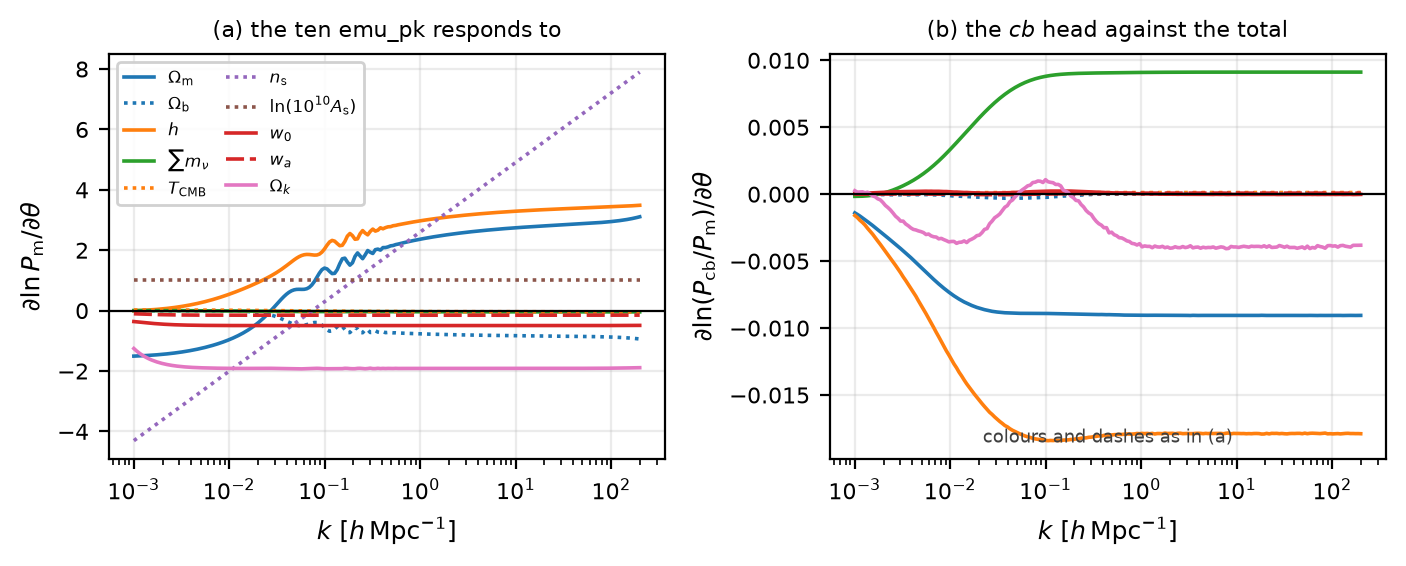

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for p in T.DPARAMS:
    colour, ls = T.DSTYLE[p]
    ax[0].semilogx(k, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
    ax[1].semilogx(k, gr[p], color=colour, ls=ls, lw=1.3)
for a in ax:
    a.axhline(0.0, color="k", lw=0.8)
    a.set_xlabel(r"$k\ [h\,\mathrm{Mpc}^{-1}]$")
ax[0].set_ylabel(r"$\partial\ln P_{\rm m}/\partial\theta$")
ax[0].legend(fontsize=6.3, ncol=2, loc="upper left", framealpha=0.9, handlelength=1.7, columnspacing=0.9)
ax[0].set_title("(a) the ten emu_pk responds to")
ax[1].set_ylabel(r"$\partial\ln(P_{\rm cb}/P_{\rm m})/\partial\theta$")
ax[1].annotate("colours and dashes as in (a)", xy=(0.5, 0.03), xycoords="axes fraction",
               ha="center", va="bottom", fontsize=6.6, color="0.25")
ax[1].set_title(r"(b) the $cb$ head against the total")
fig.tight_layout()

assert not any(np.all(g[p] == 0.0) for p in T.DPARAMS)   # none of the ten is an exact zero
T.save_figure(fig, "fig_pk_gradients")

## Cost

A forecast wants a gradient cheap enough to take many times.
The paper measures 0.47 ms for one spectrum and 0.84–0.85 ms for its gradient, on one core of an Intel Xeon Gold 6244; a laptop gives the same order.
A CLASS solve takes about 20 s, so a Fisher matrix of thousands of evaluations is seconds through the emulator and hours through the solver.

In [10]:
k200 = jnp.logspace(-3, 1, 200)
f_val = jax.jit(lambda om: pk.pk(k200, 0.0, c.replace(Omega_m=om)))
f_grad = jax.jit(jax.jacfwd(lambda om: jnp.log(pk.pk(k200, 0.0, c.replace(Omega_m=om)))))
for label, f in (("value", f_val), ("gradient", f_grad)):
    f(0.31).block_until_ready()                     # compile
    t0 = time.perf_counter()
    for _ in range(200):
        f(0.31).block_until_ready()
    print(f"{label:9s} {(time.perf_counter() - t0) / 200 * 1e3:.2f} ms")

value     0.26 ms


gradient  0.40 ms


## Exercises

1. Plot $\partial\ln P_{\rm m}/\partial\theta$ at $z = 0$, 1 and 3 for $\Omega_{\rm m}$. Why does the derivative at large scales change with redshift?
2. Take the Jacobian of $\ln P_{\rm m}$ with respect to all ten parameters at once, with `jax.jacfwd` and with `jax.jacrev`, on 31 redshifts. Compare the time and the memory; which mode does a Fisher matrix want, and why?
3. Move $\sum m_\nu$ from 0.06 to 0.3 eV and plot the change in $P_{\rm cb}/P_{\rm m}$. At which wavenumber does free streaming set in?

Next: notebook 03, the amplitude and the growth.